# Aula prática: Regressão Linear para Engenharia Elétrica

## Estimativa do consumo de energia a partir de dados horários

Neste notebook vamos usar um dataset sintético com dois anos de observações horárias. O objetivo é mostrar o fluxo completo de treinamento de um modelo de regressão linear no Python.

**Importante:** os dados foram simulados para fins didáticos. Eles não são medições reais de uma residência ou instalação elétrica.

### Objetivos
1. Carregar e explorar os dados.
2. Visualizar a relação entre temperatura e consumo.
3. Treinar uma regressão linear simples.
4. Avaliar as previsões em dados separados.
5. Analisar os resíduos.
6. Comparar com uma regressão linear múltipla.

## 1. Importar as bibliotecas

Usaremos `pandas` para manipular a tabela, `matplotlib` para gráficos e `scikit-learn` para treinar e avaliar o modelo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Carregar o CSV

Faça upload do arquivo `dataset_consumo_energia_regressao_maior.csv` no Google Colab.

Se estiver executando localmente, deixe o CSV na mesma pasta deste notebook.

In [2]:
df = pd.read_csv("dataset_consumo_energia_regressao.csv")
df.head()

,data_hora,temperatura_externa_C,hora_do_dia,dia_da_semana,fim_de_semana,consumo_energia_kWh
0,2024-01-01 00:00:00,16.57,0,0,0,1.206
1,2024-01-01 01:00:00,17.37,1,0,0,0.979
2,2024-01-01 02:00:00,18.04,2,0,0,0.688
3,2024-01-01 03:00:00,18.35,3,0,0,1.227
4,2024-01-01 04:00:00,20.41,4,0,0,1.096


## 3. Conhecer o dataset

Cada linha representa uma hora. A coluna `consumo_energia_kWh` será a variável que queremos prever.

As demais colunas descrevem possíveis fatores associados ao consumo, como temperatura, horário e dia da semana.

In [3]:
print("Dimensões:", df.shape)
print("Tipos e valores não nulos:")
df.info()

print("Estatísticas descritivas:")
display(df.describe())

Dimensões: (17520, 6)
Tipos e valores não nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   data_hora              17520 non-null  object 
 1   temperatura_externa_C  17520 non-null  float64
 2   hora_do_dia            17520 non-null  int64  
 3   dia_da_semana          17520 non-null  int64  
 4   fim_de_semana          17520 non-null  int64  
 5   consumo_energia_kWh    17520 non-null  float64
dtypes: float64(2), int64(3), object(1)
memory usage: 821.4+ KB
Estatísticas descritivas:


,temperatura_externa_C,hora_do_dia,dia_da_semana,fim_de_semana,consumo_energia_kWh
count,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000
mean,24.001359,11.500000,2.993151,0.284932,1.512500
std,5.695903,6.922384,2.001757,0.451395,0.530594
min,9.040000,0.000000,0.000000,0.000000,0.250000
25%,19.700000,5.750000,1.000000,0.000000,1.113750
50%,24.010000,11.500000,3.000000,0.000000,1.429000
75%,28.280000,17.250000,5.000000,1.000000,1.875000
max,39.000000,23.000000,6.000000,1.000000,3.576000


## 4. Verificar a qualidade dos dados

Antes do treinamento, verificamos valores ausentes e duplicados. Isso é parte importante de qualquer fluxo de análise de dados.

In [4]:
print("Valores ausentes por coluna:")
display(df.isnull().sum())

print("Linhas duplicadas:", df.duplicated().sum())

Valores ausentes por coluna:


data_hora                0
temperatura_externa_C    0
hora_do_dia              0
dia_da_semana            0
fim_de_semana            0
consumo_energia_kWh      0
dtype: int64

Linhas duplicadas: 0


## 5. Visualizar os dados

Primeiro, vamos observar uma amostra de uma semana para não sobrecarregar o gráfico. Cada ponto representa o consumo em uma hora.

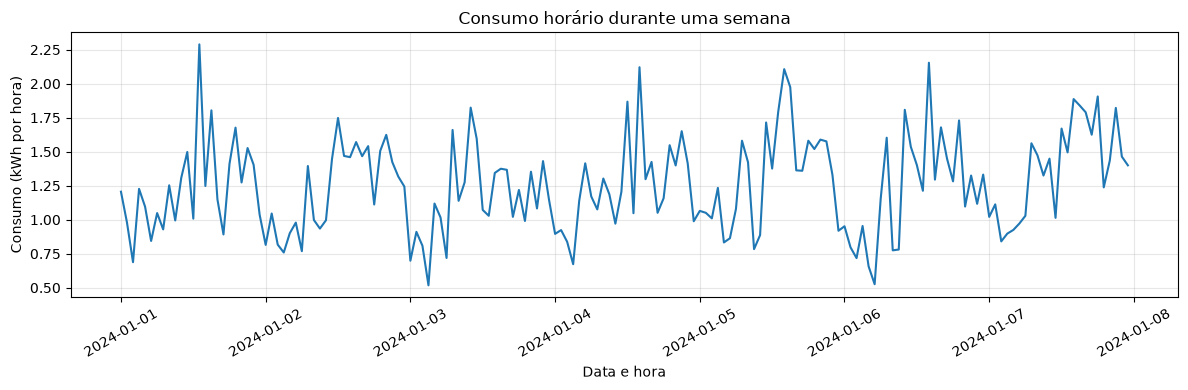

In [5]:
amostra = df.iloc[:24*7]

plt.figure(figsize=(12, 4))
plt.plot(pd.to_datetime(amostra["data_hora"]), amostra["consumo_energia_kWh"])
plt.xlabel("Data e hora")
plt.ylabel("Consumo (kWh por hora)")
plt.title("Consumo horário durante uma semana")
plt.xticks(rotation=30)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Relação entre temperatura e consumo

Um gráfico de dispersão ajuda a investigar se há uma relação aproximadamente linear entre a temperatura e o consumo. Como os dados simulados incluem outros fatores, os pontos não ficarão exatamente sobre uma reta.

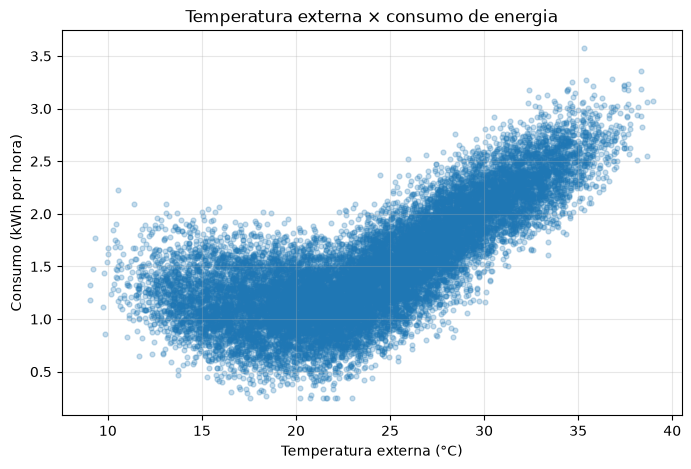

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(df["temperatura_externa_C"], df["consumo_energia_kWh"], alpha=0.25, s=12)
plt.xlabel("Temperatura externa (°C)")
plt.ylabel("Consumo (kWh por hora)")
plt.title("Temperatura externa × consumo de energia")
plt.grid(True, alpha=0.3)
plt.show()

## 6. Definir as variáveis para regressão simples

Vamos começar com apenas uma variável de entrada:

- **X:** temperatura externa.
- **y:** consumo de energia.

Esse é um bom ponto de partida para entender o funcionamento da regressão linear antes de adicionar outras variáveis.

In [8]:
X = df[["temperatura_externa_C"]] # O Pandas, usar dois colchetes [[ ]] serve para selecionar uma coluna e manter o resultado como um DataFrame (tabela), em vez de uma Series (uma única sequência de valores).
y = df["consumo_energia_kWh"]

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

Formato de X: (17520, 1)
Formato de y: (17520,)


## 7. Separar treino e teste

Vamos separar 80% dos dados para treinamento e 20% para teste.

Como o dataset tem estrutura temporal, nesta primeira demonstração faremos uma divisão aleatória para facilitar a introdução ao método. Em aplicações reais de previsão temporal, é preferível separar os dados cronologicamente para evitar usar informações futuras no treinamento.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Observações para treino:", len(X_train))
print("Observações para teste:", len(X_test))

Observações para treino: 14016
Observações para teste: 3504


## 8. Criar e treinar o modelo

`LinearRegression()` cria o modelo. O método `.fit()` ajusta os coeficientes aos dados de treinamento.

Na regressão linear simples, a equação tem a forma:

**consumo estimado = intercepto + inclinação × temperatura**

In [10]:
modelo_simples = LinearRegression()
modelo_simples.fit(X_train, y_train)

print("Treinamento concluído.")

Treinamento concluído.


## 9. Interpretar os coeficientes

O intercepto é o consumo estimado quando a temperatura é zero, embora essa interpretação possa não ser útil no contexto dos dados.

A inclinação indica a variação média estimada do consumo para cada aumento de 1 °C. Como o dataset é sintético, os coeficientes refletem as regras usadas para simulá-lo e não devem ser interpretados como uma conclusão sobre uma instalação real.

In [11]:
intercepto = modelo_simples.intercept_
inclinacao = modelo_simples.coef_[0]

print(f"Intercepto: {intercepto:.3f}")
print(f"Inclinação: {inclinacao:.4f} kWh por °C")
print(f"Equação: consumo estimado = {intercepto:.3f} + ({inclinacao:.4f} × temperatura)")

Intercepto: -0.173
Inclinação: 0.0703 kWh por °C
Equação: consumo estimado = -0.173 + (0.0703 × temperatura)


## 10. Fazer previsões e comparar com os valores reais

O método `.predict()` aplica o modelo às temperaturas do conjunto de teste. A tabela abaixo mostra algumas comparações entre o consumo observado e o estimado.

In [12]:
y_pred = modelo_simples.predict(X_test)

comparacao = X_test.copy()
comparacao["consumo_real_kWh"] = y_test
comparacao["consumo_previsto_kWh"] = y_pred
comparacao["residuo_kWh"] = comparacao["consumo_real_kWh"] - comparacao["consumo_previsto_kWh"]

display(comparacao.head(10))

,temperatura_externa_C,consumo_real_kWh,consumo_previsto_kWh,residuo_kWh
6621,18.24,1.374,1.108276,0.265724
3394,35.07,2.445,2.290885,0.154115
123,16.00,0.954,0.950876,0.003124
12074,22.80,1.033,1.428698,-0.395698
15046,20.67,1.063,1.279027,-0.216027
5608,28.46,1.753,1.826414,-0.073414
9754,28.98,1.823,1.862953,-0.039953
9976,30.40,2.495,1.962734,0.532266
2002,30.53,2.256,1.971869,0.284131
2420,31.94,2.367,2.070946,0.296054


## 11. Avaliar o modelo

- **MAE:** erro absoluto médio, em kWh. Quanto menor, melhor.
- **RMSE:** penaliza mais os erros grandes, também em kWh. Quanto menor, melhor.
- **R²:** compara o modelo com uma referência baseada na média. Quanto mais alto, melhor em geral, mas pode ser negativo no teste.

As métricas precisam ser interpretadas no contexto do problema. Como o consumo depende de outros fatores além da temperatura, a regressão simples pode ter limitações.

In [13]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f} kWh")
print(f"RMSE: {rmse:.3f} kWh")
print(f"R²:   {r2:.3f}")

MAE:  0.279 kWh
RMSE: 0.349 kWh
R²:   0.566


## Análise dos resultados

O modelo de regressão linear simples apresentou os seguintes resultados:

- **MAE:** 0,279 kWh, indicando o erro absoluto médio das previsões.
- **RMSE:** 0,349 kWh, mostrando a magnitude dos erros, com maior peso para erros elevados.
- **R²:** 0,566, indicando que o modelo explica aproximadamente 56,6% da variabilidade do consumo de energia.

Os resultados mostram que a temperatura externa ajuda a prever o consumo, mas não explica todo o seu comportamento. Como próximo passo, podemos utilizar outras variáveis, como hora do dia e dia da semana, para verificar se a regressão linear múltipla melhora as previsões.

## 12. Visualizar a reta ajustada

Os pontos mostram as observações e a linha mostra o consumo previsto pelo modelo para diferentes temperaturas.

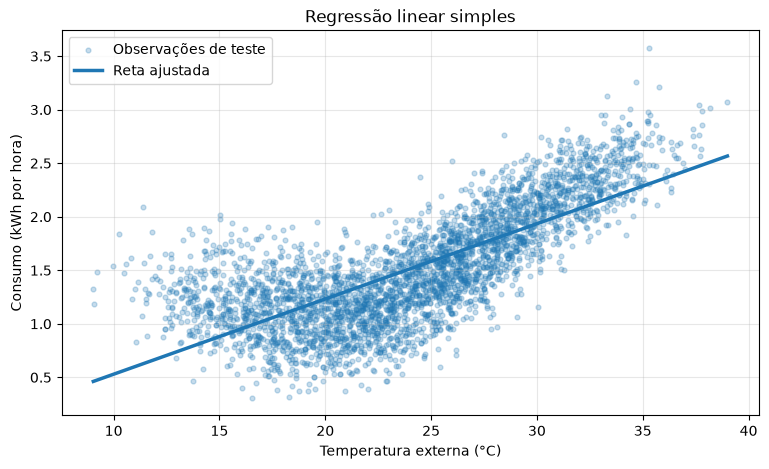

In [14]:
temperaturas_linha = pd.DataFrame({
    "temperatura_externa_C": np.linspace(
        df["temperatura_externa_C"].min(),
        df["temperatura_externa_C"].max(),
        200
    )
})
consumo_linha = modelo_simples.predict(temperaturas_linha)

plt.figure(figsize=(9, 5))
plt.scatter(X_test["temperatura_externa_C"], y_test, alpha=0.25, s=12, label="Observações de teste")
plt.plot(temperaturas_linha["temperatura_externa_C"], consumo_linha, linewidth=2.5, label="Reta ajustada")
plt.xlabel("Temperatura externa (°C)")
plt.ylabel("Consumo (kWh por hora)")
plt.title("Regressão linear simples")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 13. Analisar os resíduos

O resíduo é a diferença entre o valor real e o previsto:

**resíduo = valor real − valor previsto**

- Resíduo positivo: o modelo subestimou o consumo.
- Resíduo negativo: o modelo superestimou o consumo.
- Resíduo próximo de zero: a previsão ficou próxima do valor observado.

Se os resíduos apresentarem padrões, pode ser sinal de que a reta não está representando toda a relação existente nos dados.

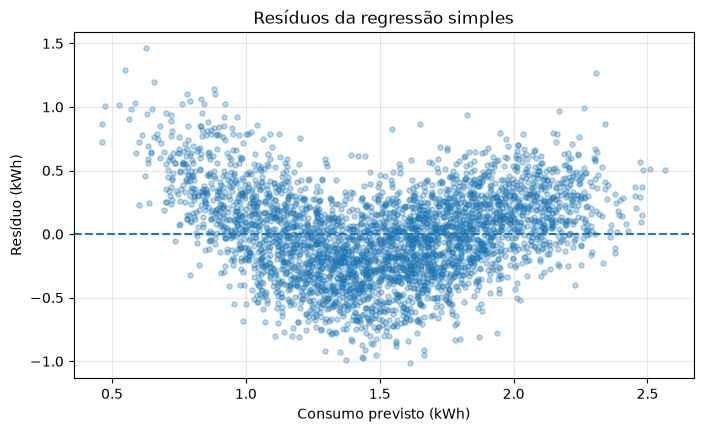

In [15]:
residuos = y_test - y_pred

plt.figure(figsize=(8, 4.5))
plt.scatter(y_pred, residuos, alpha=0.3, s=14)
plt.axhline(0, linestyle="--")
plt.xlabel("Consumo previsto (kWh)")
plt.ylabel("Resíduo (kWh)")
plt.title("Resíduos da regressão simples")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Comparação: regressão linear múltipla

Agora vamos incluir outras variáveis que podem ajudar a estimar o consumo: temperatura, hora do dia, dia da semana e indicador de fim de semana.

A regressão múltipla combina os coeficientes de todas as variáveis. Isso não garante que o modelo será melhor, por isso vamos comparar as métricas no mesmo conjunto de teste.

In [16]:
colunas_X = [
    "temperatura_externa_C",
    "hora_do_dia",
    "dia_da_semana",
    "fim_de_semana"
]

X_multi = df[colunas_X]
y = df["consumo_energia_kWh"]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y,
    test_size=0.2,
    random_state=42
)

modelo_multiplo = LinearRegression()
modelo_multiplo.fit(X_train_m, y_train_m)

y_pred_m = modelo_multiplo.predict(X_test_m)

print("Coeficientes:")
for nome, coef in zip(colunas_X, modelo_multiplo.coef_):
    print(f"{nome}: {coef:.4f}")
print(f"Intercepto: {modelo_multiplo.intercept_:.4f}")

Coeficientes:
temperatura_externa_C: 0.0649
hora_do_dia: 0.0184
dia_da_semana: -0.0036
fim_de_semana: 0.0824
Intercepto: -0.2700


## 15. Comparar os modelos

Vamos comparar MAE, RMSE e R² da regressão simples e da múltipla no conjunto de teste.

In [17]:
resultados = pd.DataFrame({
    "Modelo": ["Regressão simples", "Regressão múltipla"],
    "MAE (kWh)": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test_m, y_pred_m)
    ],
    "RMSE (kWh)": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test_m, y_pred_m))
    ],
    "R²": [
        r2_score(y_test, y_pred),
        r2_score(y_test_m, y_pred_m)
    ]
})

display(resultados.round(3))

,Modelo,MAE (kWh),RMSE (kWh),R²
0,Regressão simples,0.279,0.349,0.566
1,Regressão múltipla,0.258,0.324,0.627


## 16. Fazer uma previsão para um cenário novo

Vamos estimar o consumo para uma hora com temperatura de 30 °C, às 19h, em uma quarta-feira (dia 2 na convenção do Python, em que segunda-feira é 0), sem ser fim de semana.

A previsão é uma estimativa produzida pelo modelo, não uma garantia do consumo real.

In [18]:
novo_cenario = pd.DataFrame({
    "temperatura_externa_C": [30],
    "hora_do_dia": [19],
    "dia_da_semana": [2],
    "fim_de_semana": [0]
})

previsao_multi = modelo_multiplo.predict(novo_cenario)[0]
print(f"Consumo estimado: {previsao_multi:.3f} kWh na hora")

Consumo estimado: 2.021 kWh na hora


## 17. Perguntas para discussão

1. A inclinação da regressão simples foi positiva ou negativa?
2. O modelo que usa mais variáveis teve melhor resultado?
3. O que o MAE informa sobre o erro médio?
4. Por que é importante reservar dados para teste?
5. Por que a regressão não prova que a temperatura causa a variação do consumo?
6. Que outras variáveis reais poderiam melhorar a estimativa?

### Conclusão
O fluxo de trabalho é: conhecer os dados, visualizar relações, separar treino e teste, treinar, prever, avaliar e interpretar. O modelo deve ser escolhido com base no problema e no desempenho em dados não usados no treinamento.